In [1]:
import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
import seaborn as sns


## Capital Asset Pricing Model

CAPM - how much return based on the risk taken

Expected Return = Rf + B x (Rm - Rf)

Rf      - Risk Free Rate
Beta    - Portfolio beta vs index
Rm      - Index return
Rm - Rf - Market Risk Premium


Alpha = Actual Return - Expected Return

In [2]:
tickers = ["AAPL", "NVDA", "META", "AMZN", "TSLA", "JPM", "NKE", "SLB", "XOM" ,"JNJ", "PM", "SRE", "ELV", "ETN", "DE"]

stocks_price = yf.download(tickers, period="5y")[["Close"]] 
stocks_price.columns = ["AAPL", "NVDA", "META", "AMZN", "TSLA", "JPM", "NKE", "SLB", "XOM" ,"JNJ", "PM", "SRE", "ELV", "ETN", "DE"]
sp500 = yf.download("SPY", period="5y")["Close"]["SPY"]
risk_free_rate = float(yf.download("^TNX", period="5d")["Close"].iloc[-1].iloc[0] / 100)


stocks_returns = stocks_price.pct_change(fill_method=None).dropna()
sp500_returns = sp500.pct_change(fill_method=None).dropna()



[*********************100%***********************]  15 of 15 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


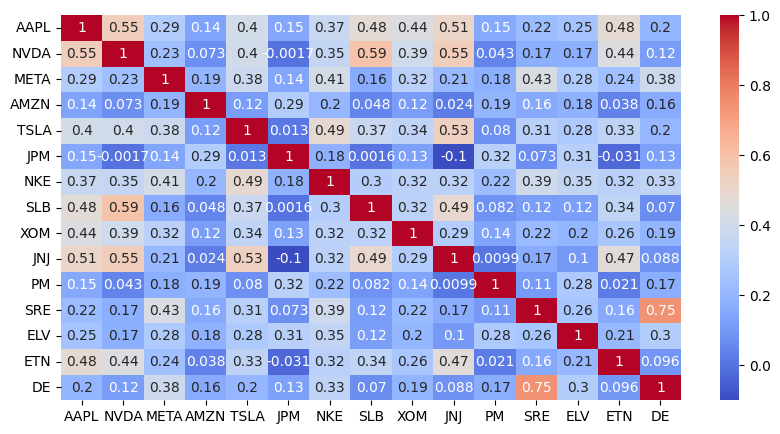

In [3]:
plt.figure(figsize=(10,5))
sns.heatmap(stocks_returns.corr(), annot=True, cmap="coolwarm")
plt.show()

In [4]:
def sortino_ratio(returns):
    annual_return = float(returns.mean() * 252)
    downside_volatility = float(returns[returns < 0].std() * np.sqrt(252 ))
    return (annual_return - risk_free_rate) / downside_volatility

In [5]:
n_simulation = 50000
n_stocks = len(stocks_returns.columns)
results = []

for i in range(n_simulation):
    weights = np.random.random(n_stocks)
    weights = weights / weights.sum()

    portfolio_return    = float(stocks_returns.dot(weights).mean() * 252)
    portfolio_risk      = float(stocks_returns.dot(weights).std() * np.sqrt(252))
    portfolio_sortino   = float(sortino_ratio(stocks_returns.dot(weights)))

    results.append([portfolio_return, portfolio_risk, portfolio_sortino, weights])

df_simulation_results = pd.DataFrame(results, columns=["Return", "Risk", "Sortino", "Weights"])    

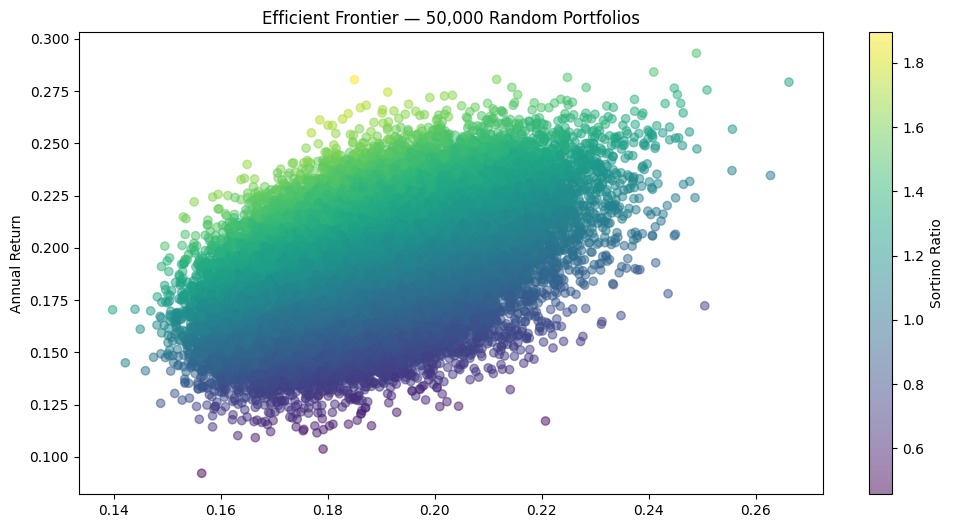

In [6]:
plt.figure(figsize=(12,6))
plt.scatter(df_simulation_results["Risk"], df_simulation_results["Return"],
            c=df_simulation_results["Sortino"], cmap="viridis", alpha=0.5)

plt.colorbar(label="Sortino Ratio")
plt.ylabel("Annual Return")
plt.title("Efficient Frontier — 50,000 Random Portfolios")
plt.show()

In [7]:
best = df_simulation_results.loc[df_simulation_results["Sortino"].idxmax()]

print(f"Best Return   : {best["Return"]*100:.2f}%")
print(f"Best Risk     : {best["Risk"]*100:.2f}%")
print(f"Best Sortino  : {best["Sortino"]:.2f}")
print(f"\nOptimal Weights:")
for ticker, weight in zip(stocks_returns.columns, best["Weights"]):
    print(f"  {ticker} : {weight*100:.2f}%")

Best Return   : 28.04%
Best Risk     : 18.50%
Best Sortino  : 1.89

Optimal Weights:
  AAPL : 1.76%
  NVDA : 0.83%
  META : 8.26%
  AMZN : 1.06%
  TSLA : 12.40%
  JPM : 16.76%
  NKE : 2.86%
  SLB : 0.60%
  XOM : 0.62%
  JNJ : 20.49%
  PM : 13.74%
  SRE : 7.57%
  ELV : 3.92%
  ETN : 2.10%
  DE : 7.02%


In [8]:
selected_weights    = best["Weights"]
portfolio_returns   = stocks_returns.dot(selected_weights)

portfolio_returns, sp500_returns = portfolio_returns.align(sp500_returns, join="inner")

covariance  = portfolio_returns.cov(sp500_returns)
variance    = sp500_returns.var()
beta        = covariance / variance

print(f"Porfolio Beta: {beta:.2f}")


Porfolio Beta: 0.97


### CAPM

In [9]:
rf = risk_free_rate
rm = float(sp500_returns.mean() * 252)
expected_return = rf + beta * (rm - rf)

print(f"Risk Free Rate    : {rf * 100:.2f}%")
print(f"Market Return     : {rm * 100:.2f}%")
print(f"Beta              : {beta:.2f}")
print(f"Expected Return   : {expected_return * 100:.2f}%")

Risk Free Rate    : 4.28%
Market Return     : 13.13%
Beta              : 0.97
Expected Return   : 12.85%


### Alpha

In [10]:
actual_return = float(portfolio_returns.mean() * 252)
alpha = actual_return - expected_return

print(f"Actual Return   : {actual_return * 100:.2f}%")
print(f"Expected Return : {expected_return * 100:.2f}%")
print(f"Alpha           : {alpha * 100:.2f}%")

Actual Return   : 28.04%
Expected Return : 12.85%
Alpha           : 15.19%


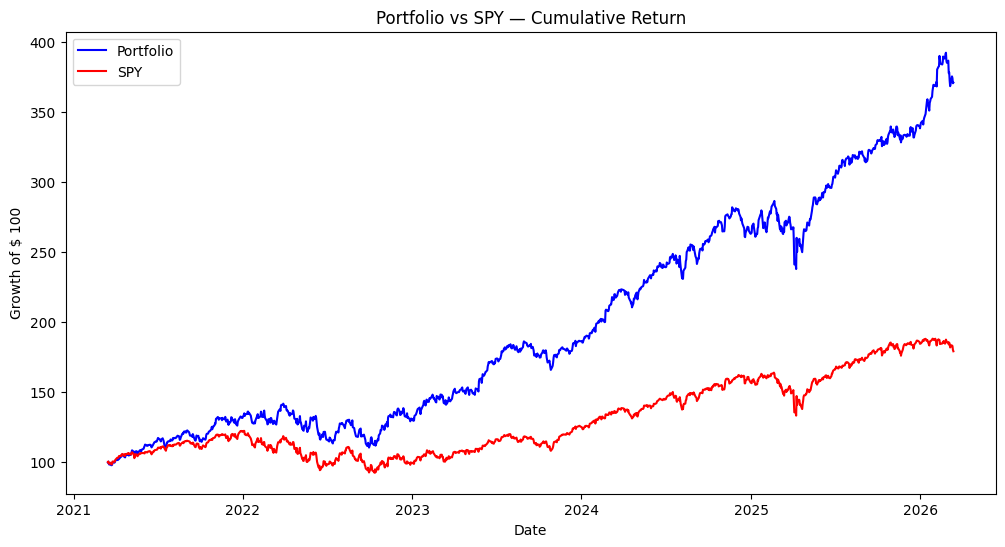

In [19]:

capital = 100
portfolio_cumulative = (1 + portfolio_returns).cumprod() * capital
spy_cumulative = (1 + sp500_returns).cumprod() * capital

plt.figure(figsize=(12,6))
plt.plot(portfolio_cumulative, label="Portfolio", color="blue")
plt.plot(spy_cumulative, label="SPY", color="red")
plt.title("Portfolio vs SPY — Cumulative Return")
plt.ylabel(f"Growth of $ {capital:,}")
plt.xlabel("Date")
plt.legend()
plt.show()